<a href="https://colab.research.google.com/github/MHassanEjaz/rag-project/blob/main/notebooks/rag-project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install datasets pandas

In [2]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("gfissore/arxiv-abstracts-2021", split="train", streaming=True)
rows = [x for _, x in zip(range(20000), ds)]
df = pd.DataFrame(rows)

print(df.shape)
print(df.head())

README.md:   0%|          | 0.00/6.75k [00:00<?, ?B/s]

(20000, 11)
          id           submitter  \
0  0704.0001      Pavel Nadolsky   
1  0704.0002        Louis Theran   
2  0704.0003         Hongjun Pan   
3  0704.0004        David Callan   
4  0704.0005  Alberto Torchinsky   

                                             authors  \
0  C. Bal\'azs, E. L. Berger, P. M. Nadolsky, C.-...   
1                    Ileana Streinu and Louis Theran   
2                                        Hongjun Pan   
3                                       David Callan   
4           Wael Abu-Shammala and Alberto Torchinsky   

                                               title  \
0  Calculation of prompt diphoton production cros...   
1           Sparsity-certifying Graph Decompositions   
2  The evolution of the Earth-Moon system based o...   
3  A determinant of Stirling cycle numbers counts...   
4  From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...   

                                  comments  \
0  37 pages, 15 figures; published version   
1    

id                 0
submitter          0
authors            0
title              0
comments        2349
journal-ref     9500
doi             7415
abstract           0
report-no      18107
categories         0
versions           0
dtype: int64
count    20000.000000
mean       121.421200
std         62.869413
min          2.000000
25%         76.000000
50%        109.000000
75%        158.000000
max        342.000000
Name: word_count, dtype: float64


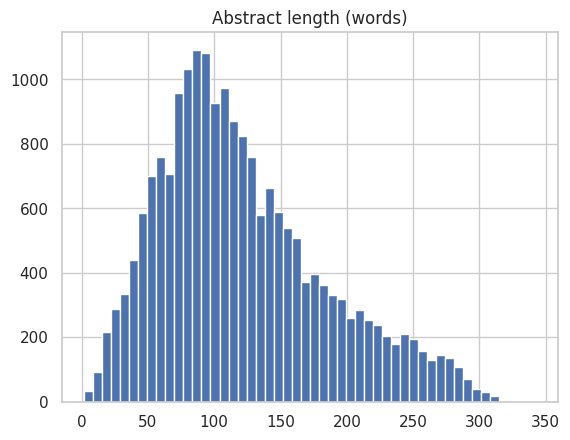

Duplicate abstracts: 21
main_cat
astro-ph              3606
hep-ph                1400
hep-th                1271
quant-ph              1133
gr-qc                  683
cond-mat.mes-hall      674
cond-mat.mtrl-sci      620
cond-mat.str-el        596
cond-mat.stat-mech     510
math.AG                405
math-ph                400
nucl-th                373
cond-mat.supr-con      365
cond-mat.other         365
hep-ex                 360
Name: count, dtype: int64


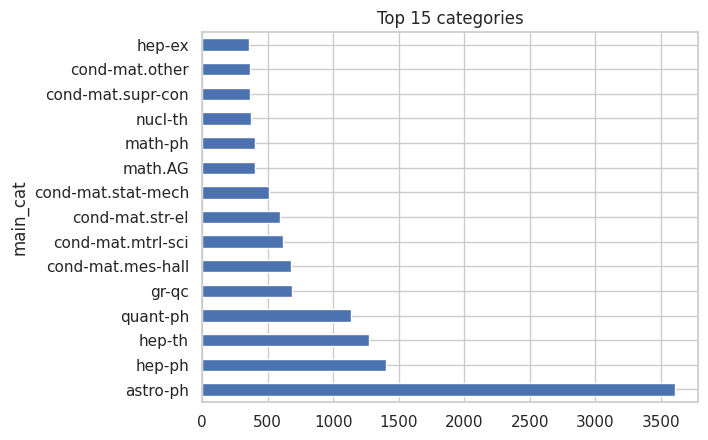

AI/ML papers: 116


In [4]:
import matplotlib.pyplot as plt

# 1. Missing values
print(df.isnull().sum())

# 2. Abstract length
df["abstract"] = df["abstract"].str.strip()
df["word_count"] = df["abstract"].str.split().str.len()
print(df["word_count"].describe())
df["word_count"].hist(bins=50)
plt.title("Abstract length (words)")
plt.show()

# 3. Duplicates
print("Duplicate abstracts:", df.duplicated(subset="abstract").sum())

# 4. Top categories (pehli category lo)
df["main_cat"] = df["categories"].apply(lambda x: x[0].split()[0] if len(x) else None)
print(df["main_cat"].value_counts().head(15))
df["main_cat"].value_counts().head(15).plot(kind="barh")
plt.title("Top 15 categories")
plt.show()

# 5. AI/ML papers kitne hain
ai = df[df["categories"].apply(lambda x: any(c.startswith(("cs.AI","cs.LG","cs.CL")) for c in " ".join(x).split()))]
print("AI/ML papers:", len(ai))

In [5]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
N_ROWS = 20000
RANDOM_STATE = 42
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
results = {}
cleaning_log = []

def as_text(x):
    return " ".join(map(str, x)) if isinstance(x, (list, tuple, np.ndarray)) else str(x)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def log(column, problem, action, reason):
    cleaning_log.append({"column": column, "problem": problem, "action": action, "reason": reason})

In [6]:
from datasets import load_dataset
ds = load_dataset("gfissore/arxiv-abstracts-2021", split="train", streaming=True)
raw = pd.DataFrame([row for _, row in zip(range(N_ROWS), ds)])
raw.to_csv("data/arxiv_sample.csv", index=False)
raw.shape

(20000, 11)

In [7]:
n_cols_original = raw.shape[1]
for c in ["authors", "categories", "versions"]:
    raw[c] = raw[c].apply(as_text)

def to_field(cat):
    for prefix, name in [("astro-ph", "astro-ph"), ("hep-", "hep"), ("cond-mat", "cond-mat"), ("quant-ph", "quant-ph"),
                         ("gr-qc", "gr-qc"), ("nucl-", "nucl"), ("math", "math"), ("physics", "physics"),
                         ("cs.", "cs"), ("q-bio", "q-bio"), ("stat", "stat")]:
        if cat.startswith(prefix):
            return name
    return "other"

raw["field"] = raw["categories"].apply(lambda c: to_field(c.split()[0]))
small = raw["field"].value_counts()
small = small[small < 500].index
raw["field"] = raw["field"].replace(dict.fromkeys(small, "other"))

print("Shape:", raw.shape)
raw.info()

Shape: (20000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           20000 non-null  object
 1   submitter    20000 non-null  object
 2   authors      20000 non-null  object
 3   title        20000 non-null  object
 4   comments     17651 non-null  object
 5   journal-ref  10500 non-null  object
 6   doi          12585 non-null  object
 7   abstract     20000 non-null  object
 8   report-no    1893 non-null   object
 9   categories   20000 non-null  object
 10  versions     20000 non-null  object
 11  field        20000 non-null  object
dtypes: object(12)
memory usage: 1.8+ MB


In [8]:
display(raw.head())
display(raw.describe(include="all").T)

,id,submitter,authors,title,comments,journal-ref,doi,abstract,report-no,categories,versions,field
0,0704.0001,Pavel Nadolsky,"C. Bal\'azs, E. L. Berger, P. M. Nadolsky, C.-...",Calculation of prompt diphoton production cros...,"37 pages, 15 figures; published version","Phys.Rev.D76:013009,2007",10.1103/PhysRevD.76.013009,A fully differential calculation in perturba...,ANL-HEP-PR-07-12,hep-ph,v1 v2,hep
1,0704.0002,Louis Theran,Ileana Streinu and Louis Theran,Sparsity-certifying Graph Decompositions,To appear in Graphs and Combinatorics,None,None,"We describe a new algorithm, the $(k,\ell)$-...",None,math.CO cs.CG,v1 v2,math
2,0704.0003,Hongjun Pan,Hongjun Pan,The evolution of the Earth-Moon system based o...,"23 pages, 3 figures",None,None,The evolution of Earth-Moon system is descri...,None,physics.gen-ph,v1 v2 v3,physics
3,0704.0004,David Callan,David Callan,A determinant of Stirling cycle numbers counts...,11 pages,None,None,We show that a determinant of Stirling cycle...,None,math.CO,v1,math
4,0704.0005,Alberto Torchinsky,Wael Abu-Shammala and Alberto Torchinsky,From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...,None,"Illinois J. Math. 52 (2008) no.2, 681-689",None,In this paper we show how to compute the $\L...,None,math.CA math.FA,v1,math


,count,unique,top,freq
id,20000,20000,0708.2132,1
submitter,20000,14552,Damien Chablat,69
authors,20000,18434,"The BABAR Collaboration: B. Aubert, et al",22
title,20000,19989,Discussion of ``2004 IMS Medallion Lecture: Lo...,5
comments,17651,12999,"4 pages, 4 figures",136
journal-ref,10500,10444,"Dans European Nano Systems Worshop - ENS 2005,...",24
doi,12585,12574,10.1103/PhysRevLett.99.071302,4
abstract,20000,19979,Discussion of ``2004 IMS Medallion Lecture: ...,5
report-no,1893,1885,GFL-001,4
categories,20000,2199,astro-ph,3345


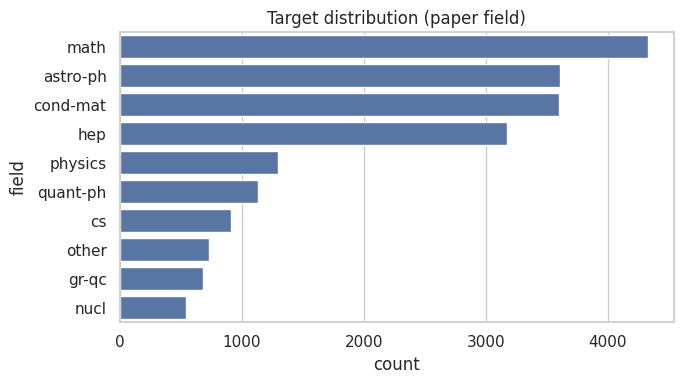

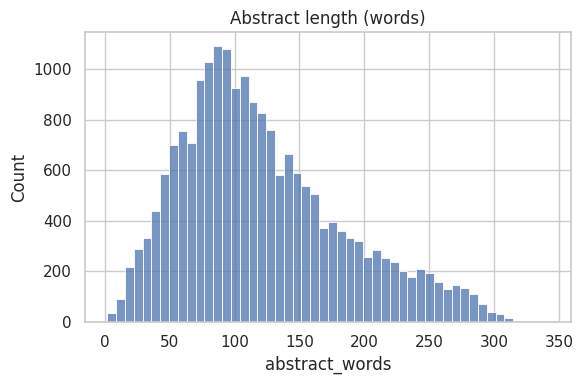

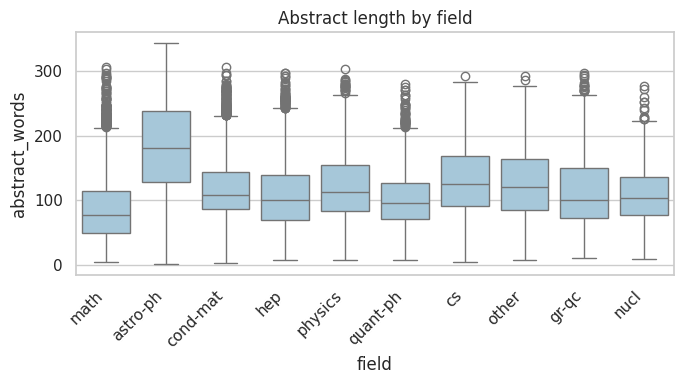

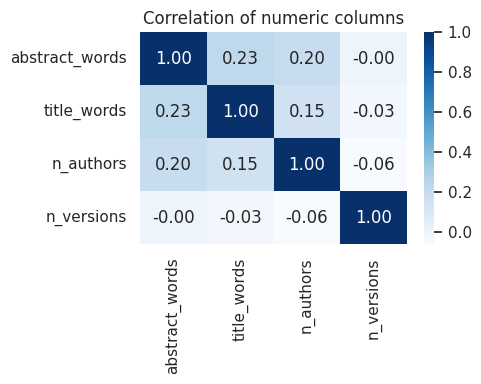

In [9]:
raw["abstract"] = raw["abstract"].str.strip()
raw["abstract_words"] = raw["abstract"].str.split().str.len()
raw["title_words"] = raw["title"].str.split().str.len()
raw["n_authors"] = raw["authors"].apply(lambda a: len([p for p in re.split(r",|\band\b", a) if p.strip()]))
raw["n_versions"] = raw["versions"].apply(lambda v: len(re.findall(r"v\d+", v)))

order = raw["field"].value_counts().index
plt.figure(figsize=(7, 4))
sns.countplot(data=raw, y="field", order=order, color="#4c72b0")
plt.title("Target distribution (paper field)")
save_fig("fig_target")

plt.figure(figsize=(6, 4))
sns.histplot(raw["abstract_words"], bins=50, color="#4c72b0")
plt.title("Abstract length (words)")
save_fig("fig_abstract_hist")

plt.figure(figsize=(7, 4))
sns.boxplot(data=raw, x="field", y="abstract_words", order=order, color="#9ecae1")
plt.xticks(rotation=45, ha="right")
plt.title("Abstract length by field")
save_fig("fig_box_by_field")

plt.figure(figsize=(5, 4))
sns.heatmap(raw[["abstract_words", "title_words", "n_authors", "n_versions"]].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation of numeric columns")
save_fig("fig_corr")

In [10]:
share = raw["field"].value_counts(normalize=True)
med = raw.groupby("field")["abstract_words"].median().sort_values()
results["eda_notes"] = [
    f"The largest class is '{share.index[0]}' with {share.iloc[0]*100:.1f}% of the papers; the smallest is '{share.index[-1]}' with {share.iloc[-1]*100:.1f}%, so the classes are imbalanced.",
    f"Abstracts have a median of {raw['abstract_words'].median():.0f} words (max {raw['abstract_words'].max()}); '{med.index[0]}' papers have the shortest median abstract ({med.iloc[0]:.0f}) and '{med.index[-1]}' the longest ({med.iloc[-1]:.0f}).",
    (lambda m: f"The largest absolute correlation between two numeric columns is {m:.2f}, so " + ("they are only weakly related and none looks redundant." if m < 0.3 else "some of them are related; I keep them but a model may not gain much from both."))(raw[["abstract_words", "title_words", "n_authors", "n_versions"]].corr().abs().where(~np.eye(4, dtype=bool)).max().max()),
]
results["eda_notes"]

["The largest class is 'math' with 21.6% of the papers; the smallest is 'nucl' with 2.7%, so the classes are imbalanced.",
 "Abstracts have a median of 109 words (max 342); 'math' papers have the shortest median abstract (77) and 'astro-ph' the longest (180).",
 'The largest absolute correlation between two numeric columns is 0.23, so they are only weakly related and none looks redundant.']

Rows before: 20000, duplicates removed: 21, rows after: 19979
             missing  percent
comments        2347     11.7
journal-ref     9488     47.5
doi             7404     37.1
report-no      18093     90.6


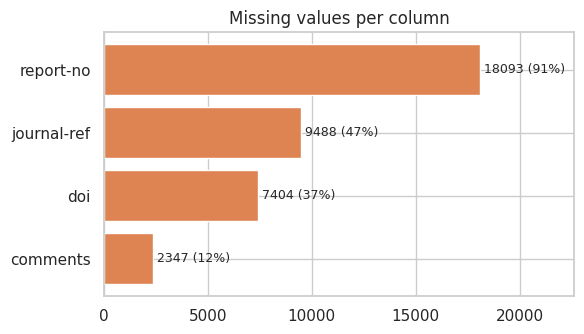

In [11]:
n_before = len(raw)
n_dups = int(raw.duplicated(subset="abstract").sum())
df = raw.drop_duplicates(subset="abstract").reset_index(drop=True)
print(f"Rows before: {n_before}, duplicates removed: {n_dups}, rows after: {len(df)}")

missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
print(pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0])

m = missing[missing > 0].sort_values()
plt.figure(figsize=(6, 3.5))
plt.barh(m.index, m.values, color="#dd8452")
for i, v in enumerate(m.values):
    plt.text(v, i, f" {v} ({v/len(df)*100:.0f}%)", va="center", fontsize=9)
plt.title("Missing values per column")
plt.xlim(0, m.max() * 1.25)
save_fig("fig_missing")

In [12]:
pct = lambda c: f"{df[c].isna().mean()*100:.0f}% missing"

log("abstract", f"{n_dups} duplicate abstracts", "Dropped the duplicate rows",
    "The same text in train and test would make the test score look better than it is")
log("id", "Identifier, no meaning for the model", "Dropped", "A paper id is just a label; it also encodes the submission date")
log("submitter", "Free-text name with thousands of different values", "Dropped", "Too many unique values to encode, and not related to the subject")
log("report-no", f"{pct('report-no')}", "Dropped the column", "Almost always empty, so there is nothing to learn from and filling it would be guessing")
log("categories", "This column is where the target comes from", "Dropped from X",
    "Keeping it would leak the answer into the inputs")
log("comments", f"{pct('comments')}", "Extracted pages and figures (Step 3); numbers that are not mentioned stay missing and get the median later",
    "A missing value here means the author did not say, so the median is a neutral guess")
log("journal-ref", f"{pct('journal-ref')}", "Made has_journal_ref and journal_family; missing journal becomes 'unpublished'",
    "Here a missing value carries real meaning (not published yet), so a label is better than guessing")
log("doi", f"{pct('doi')}", "Made has_doi and doi_prefix; missing prefix stays missing and gets the most frequent value later",
    "The has_doi flag already keeps the information, so filling the prefix cannot hide anything")
log("authors, title, versions", "Raw text / lists, not usable directly", "Replaced by counts (n_authors, title_words, n_versions)",
    "Counts are simple numbers a model can use")

In [13]:
c = df["comments"].fillna("").str.lower()
df["pages"] = pd.to_numeric(c.str.extract(r"(\d+)\s*pages")[0], errors="coerce")
df["figures"] = pd.to_numeric(c.str.extract(r"(\d+)\s*(?:figures|figs?)")[0], errors="coerce")
df["math_symbols"] = df["abstract"].str.count(r"\$")

df["has_journal_ref"] = np.where(df["journal-ref"].notna(), "yes", "no")
df["has_doi"] = np.where(df["doi"].notna(), "yes", "no")

def journal_family(s):
    if pd.isna(s):
        return "unpublished"
    m = re.match(r"[A-Za-z][A-Za-z.\s&]*", s.strip())
    return re.sub(r"\s+", " ", m.group(0)).strip(" .").lower() if m else "unknown"

df["journal_family"] = df["journal-ref"].apply(journal_family)
df["doi_prefix"] = df["doi"].str.extract(r"^(10\.\d+)")[0]

new_features = {
    "pages": "number of pages mentioned by the authors",
    "figures": "number of figures mentioned by the authors",
    "math_symbols": "count of '$' (LaTeX math) in the abstract",
    "has_journal_ref": "yes/no: paper has a journal reference",
    "has_doi": "yes/no: paper has a DOI",
    "journal_family": "journal name without volume and year",
    "doi_prefix": "publisher part of the DOI",
}
results["new_features"] = new_features
df[list(new_features)].head()

,pages,figures,math_symbols,has_journal_ref,has_doi,journal_family,doi_prefix
0,37.0,15.0,0,yes,yes,phys.rev.d,10.1103
1,NaN,NaN,6,no,no,unpublished,NaN
2,23.0,3.0,0,no,no,unpublished,NaN
3,11.0,NaN,0,no,no,unpublished,NaN
4,NaN,NaN,6,yes,no,illinois j. math,NaN


In [14]:
num_cols = ["abstract_words", "title_words", "n_authors", "n_versions", "pages", "figures", "math_symbols"]
cat_cols = ["journal_family", "doi_prefix", "has_journal_ref", "has_doi"]

X = df[num_cols + cat_cols]
y = df["field"]
print("X:", X.shape, " y:", y.shape)
X.isna().sum()

X: (19979, 11)  y: (19979,)


,0
abstract_words,0
title_words,0
n_authors,0
n_versions,0
pages,5562
figures,10449
math_symbols,0
journal_family,0
doi_prefix,7404
has_journal_ref,0


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train size:", len(X_train), " Test size:", len(X_test))
props = pd.DataFrame({"train": y_train.value_counts(normalize=True).round(3),
                      "test": y_test.value_counts(normalize=True).round(3)})
display(props)
results["split"] = {"train": int(len(X_train)), "test": int(len(X_test)),
                    "proportions": props.reset_index().rename(columns={"field": "class"}).to_dict("records")}

Train size: 15983  Test size: 3996


,train,test
field,,
math,0.216,0.216
astro-ph,0.180,0.180
cond-mat,0.180,0.180
hep,0.159,0.159
physics,0.065,0.065
quant-ph,0.057,0.057
cs,0.045,0.046
other,0.036,0.036
gr-qc,0.034,0.034


In [16]:
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False))])

preprocess = ColumnTransformer([("num", num_pipe, num_cols),
                                ("cat", cat_pipe, cat_cols)])

X_train_arr = preprocess.fit_transform(X_train)
X_test_arr = preprocess.transform(X_test)

names = preprocess.get_feature_names_out()
X_train = pd.DataFrame(X_train_arr, columns=names, index=X_train.index)
X_test = pd.DataFrame(X_test_arr, columns=names, index=X_test.index)
X_train.head()

,num__abstract_words,num__title_words,num__n_authors,num__n_versions,num__pages,num__figures,num__math_symbols,cat__journal_family_aip conf.proc,cat__journal_family_aipconf.proc,cat__journal_family_annals of statistics,...,cat__doi_prefix_10.1142,cat__doi_prefix_10.1143,cat__doi_prefix_10.1209,cat__doi_prefix_10.1214,cat__doi_prefix_10.1364,cat__doi_prefix_infrequent_sklearn,cat__has_journal_ref_no,cat__has_journal_ref_yes,cat__has_doi_no,cat__has_doi_yes
545,2.350148,2.510294,0.571520,0.321024,-0.219775,-0.163961,-0.361826,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
7596,-0.247889,0.384300,-0.306153,-0.452056,-0.090697,-0.163961,-0.361826,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3871,1.361938,0.915798,-0.525572,-0.452056,-0.477932,0.499368,3.934533,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
7429,-0.502911,-0.147199,-0.306153,-0.452056,0.102920,0.278258,-0.361826,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
8785,-0.726055,-0.412948,-0.086735,0.321024,-0.671549,-0.385071,-0.361826,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


In [17]:
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)

miss_train, miss_test = int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum())
print("Missing values in X_train:", miss_train, " in X_test:", miss_test)
assert miss_train == 0 and miss_test == 0

raw_train_X = df.loc[X_train.index, num_cols]
raw_test_X = df.loc[X_test.index, num_cols]
imp = preprocess.named_transformers_["num"].named_steps["impute"]
scaler = preprocess.named_transformers_["num"].named_steps["scale"]
print("Imputer medians equal the TRAIN medians:", np.allclose(imp.statistics_, raw_train_X.median().values))
print("Imputer medians equal the TEST medians :", np.allclose(imp.statistics_, raw_test_X.median().values), "(should be False)")
print("Scaler saw only train rows:", scaler.n_samples_seen_ == len(X_train), f"({scaler.n_samples_seen_} rows)")
assert scaler.n_samples_seen_ == len(X_train)

results["final"] = {
    "X_train": list(X_train.shape), "X_test": list(X_test.shape),
    "y_train": list(y_train.shape), "y_test": list(y_test.shape),
    "missing_train": miss_train, "missing_test": miss_test,
    "n_numeric_features": len(num_cols), "n_categorical_columns": len(cat_cols),
    "n_encoded_features": int(X_train.shape[1]),
}
results["dataset"] = {
    "rows_raw": int(n_before), "rows_clean": int(len(df)), "columns_raw": int(n_cols_original),
    "duplicates": n_dups, "target": "field", "classes": sorted(y.unique().tolist()),
    "class_counts": y.value_counts().to_dict(),
}
results["cleaning_log"] = cleaning_log
with open("outputs/results.json", "w") as f:
    json.dump(results, f, indent=2, default=int)
print("Saved outputs/results.json")

X_train: (15983, 78)  X_test: (3996, 78)
y_train: (15983,)  y_test: (3996,)
Missing values in X_train: 0  in X_test: 0
Imputer medians equal the TRAIN medians: True
Imputer medians equal the TEST medians : False (should be False)
Scaler saw only train rows: True (15983 rows)
Saved outputs/results.json


In [18]:
!zip -r results_files.zip figures outputs
from google.colab import files
files.download("results_files.zip")

  adding: figures/ (stored 0%)
  adding: figures/fig_corr.png (deflated 8%)
  adding: figures/fig_box_by_field.png (deflated 13%)
  adding: figures/fig_abstract_hist.png (deflated 18%)
  adding: figures/fig_target.png (deflated 18%)
  adding: figures/fig_missing.png (deflated 18%)
  adding: outputs/ (stored 0%)
  adding: outputs/results.json (deflated 67%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_recall_fscore_support, f1_score, mean_absolute_error, r2_score)

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")
w3 = {}   # numbers saved at the end for the report

def save_fig3(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Duplicate abstracts left in df:", int(df.duplicated(subset="abstract").sum()))
miss = df[num_cols + cat_cols].isna().sum()
print("Missing values per model column (filled inside the pipeline below):")
print(miss[miss > 0])

Duplicate abstracts left in df: 0
Missing values per model column (filled inside the pipeline below):
pages          5562
figures       10449
doi_prefix     7404
dtype: int64


,rows,percent
field,,
math,4321,21.6
astro-ph,3604,18.0
cond-mat,3595,18.0
hep,3169,15.9
physics,1297,6.5
quant-ph,1131,5.7
cs,908,4.5
other,727,3.6
gr-qc,683,3.4


The biggest class ('math') is 7.9 times bigger than the smallest ('nucl').


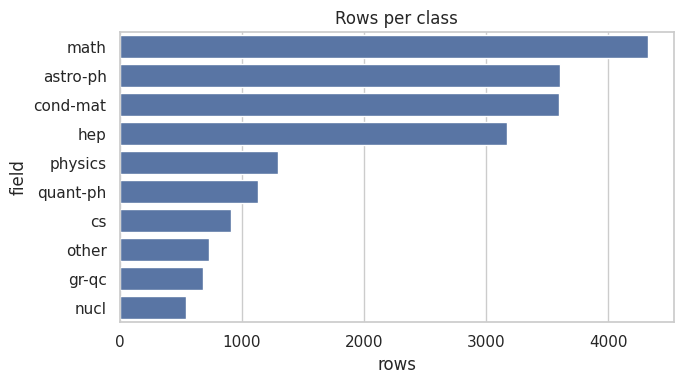

In [20]:
counts = df["field"].value_counts()
balance = pd.DataFrame({"rows": counts, "percent": (counts / len(df) * 100).round(1)})
display(balance)
ratio = counts.max() / counts.min()
print(f"The biggest class ('{counts.index[0]}') is {ratio:.1f} times bigger than the smallest ('{counts.index[-1]}').")

plt.figure(figsize=(7, 4))
sns.barplot(x=counts.values, y=counts.index, color="#4c72b0")
plt.title("Rows per class")
plt.xlabel("rows")
save_fig3("w3_class_balance")

w3["dataset"] = {"rows": int(len(df)), "n_numeric": len(num_cols), "n_categorical": len(cat_cols),
                 "target": "field", "classes": counts.index.tolist(),
                 "class_counts": {k: int(v) for k, v in counts.items()}, "ratio_big_small": float(ratio)}

In [21]:
X = df[num_cols + cat_cols]
y = df["field"]
X_train_raw, X_test_raw, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

prep3 = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False))]), cat_cols),
])
Xtr = pd.DataFrame(prep3.fit_transform(X_train_raw), columns=prep3.get_feature_names_out(), index=X_train_raw.index)  # fit on train
Xte = pd.DataFrame(prep3.transform(X_test_raw), columns=prep3.get_feature_names_out(), index=X_test_raw.index)       # only transform

print("Train:", Xtr.shape, " Test:", Xte.shape)
print("Missing values left:", int(Xtr.isna().sum().sum()), int(Xte.isna().sum().sum()))
print(pd.DataFrame({"train": ytr.value_counts(normalize=True).round(3), "test": yte.value_counts(normalize=True).round(3)}))
classes = sorted(y.unique().tolist())
w3["split"] = {"train": int(len(Xtr)), "test": int(len(Xte)), "n_features": int(Xtr.shape[1])}

Train: (15983, 78)  Test: (3996, 78)
Missing values left: 0 0
          train   test
field                 
math      0.216  0.216
astro-ph  0.180  0.180
cond-mat  0.180  0.180
hep       0.159  0.159
physics   0.065  0.065
quant-ph  0.057  0.057
cs        0.045  0.046
other     0.036  0.036
gr-qc     0.034  0.034
nucl      0.027  0.027


KNN with K=5, test accuracy: 0.5903


,K,cv_accuracy,test_accuracy
0,1,0.5101,0.5183
1,3,0.5427,0.5561
2,5,0.5692,0.5903
3,7,0.5829,0.6019
4,9,0.5874,0.6076
5,11,0.5919,0.6126
6,13,0.5943,0.6179
7,15,0.5950,0.6211


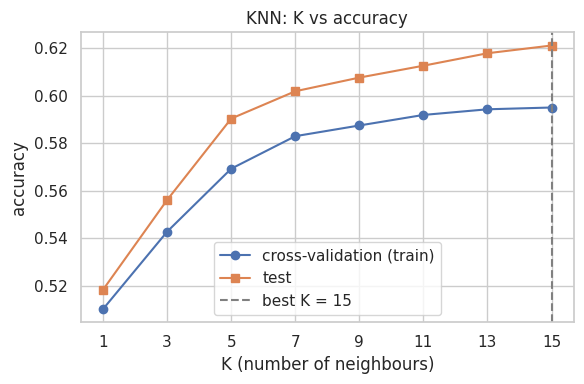

Best K (by cross-validation): 15


In [22]:
knn5 = KNeighborsClassifier(n_neighbors=5).fit(Xtr, ytr)
print("KNN with K=5, test accuracy:", round(knn5.score(Xte, yte), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for k in range(1, 16, 2):
    m = KNeighborsClassifier(n_neighbors=k)
    cv_acc = cross_val_score(m, Xtr, ytr, cv=cv, n_jobs=-1).mean()
    test_acc = m.fit(Xtr, ytr).score(Xte, yte)
    rows.append({"K": k, "cv_accuracy": cv_acc, "test_accuracy": test_acc})
knn_table = pd.DataFrame(rows)
display(knn_table.round(4))

best_k = int(knn_table.loc[knn_table["cv_accuracy"].idxmax(), "K"])
plt.figure(figsize=(6, 4))
plt.plot(knn_table["K"], knn_table["cv_accuracy"], marker="o", label="cross-validation (train)")
plt.plot(knn_table["K"], knn_table["test_accuracy"], marker="s", label="test")
plt.axvline(best_k, color="gray", linestyle="--", label=f"best K = {best_k}")
plt.xticks(knn_table["K"]); plt.xlabel("K (number of neighbours)"); plt.ylabel("accuracy")
plt.title("KNN: K vs accuracy"); plt.legend()
save_fig3("w3_knn_k")
print("Best K (by cross-validation):", best_k)

knn = KNeighborsClassifier(n_neighbors=best_k).fit(Xtr, ytr)
w3["knn"] = {"table": knn_table.round(4).to_dict("records"), "best_k": best_k, "acc_k5": float(knn5.score(Xte, yte))}

,max_depth,train_accuracy,cv_accuracy,test_accuracy,real_depth,leaves
0,2,0.3690,0.3686,0.3766,2,4
1,3,0.4024,0.4016,0.4067,3,8
2,5,0.4681,0.4613,0.4660,5,27
3,10,0.5784,0.5294,0.5468,10,402
4,None,0.9978,0.5031,0.5218,52,6251


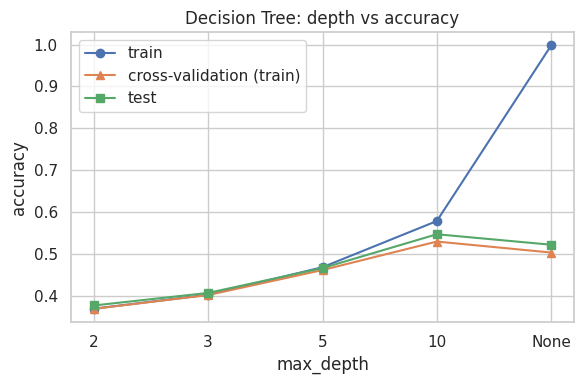

Best max_depth (by cross-validation): 10
Unlimited tree: depth 52, 6251 leaves, train accuracy 0.998 vs test accuracy 0.522


In [23]:
rows = []
for d in [2, 3, 5, 10, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_acc = cross_val_score(t, Xtr, ytr, cv=cv, n_jobs=-1).mean()
    t.fit(Xtr, ytr)
    rows.append({"max_depth": "None" if d is None else str(d), "train_accuracy": t.score(Xtr, ytr), "cv_accuracy": cv_acc,
                 "test_accuracy": t.score(Xte, yte), "real_depth": t.get_depth(), "leaves": t.get_n_leaves()})
tree_table = pd.DataFrame(rows)
display(tree_table.round(4))

best_idx = int(np.argmax(tree_table["cv_accuracy"].values))      # first (shallowest) one wins ties
best_depth_label = tree_table.loc[best_idx, "max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)

plt.figure(figsize=(6, 4))
plt.plot(tree_table["max_depth"], tree_table["train_accuracy"], marker="o", label="train")
plt.plot(tree_table["max_depth"], tree_table["cv_accuracy"], marker="^", label="cross-validation (train)")
plt.plot(tree_table["max_depth"], tree_table["test_accuracy"], marker="s", label="test")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Decision Tree: depth vs accuracy"); plt.legend()
save_fig3("w3_tree_depth")

deep = tree_table[tree_table["max_depth"] == "None"].iloc[0]
print(f"Best max_depth (by cross-validation): {best_depth_label}")
print(f"Unlimited tree: depth {int(deep.real_depth)}, {int(deep.leaves)} leaves, train accuracy {deep.train_accuracy:.3f} vs test accuracy {deep.test_accuracy:.3f}")

tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42).fit(Xtr, ytr)
w3["tree"] = {"table": tree_table.round(4).to_dict("records"), "best_depth": best_depth_label}

In [24]:
logreg = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
raw_proba = logreg.predict_proba(Xte.iloc[:5])
proba = pd.DataFrame(raw_proba, columns=logreg.classes_).round(3)
proba["predicted"] = logreg.predict(Xte.iloc[:5])
proba["actual"] = yte.iloc[:5].values
display(proba)
print("Row sums:", raw_proba.sum(axis=1).round(3).tolist())

,astro-ph,cond-mat,cs,gr-qc,hep,math,nucl,other,physics,quant-ph,predicted,actual
0,0.104,0.176,0.117,0.026,0.128,0.110,0.027,0.065,0.202,0.045,physics,cs
1,0.028,0.073,0.036,0.023,0.082,0.620,0.019,0.037,0.063,0.020,math,math
2,0.100,0.107,0.129,0.022,0.098,0.317,0.021,0.056,0.083,0.068,math,hep
3,0.290,0.093,0.274,0.015,0.024,0.059,0.005,0.095,0.110,0.034,astro-ph,other
4,0.035,0.141,0.021,0.029,0.122,0.401,0.019,0.041,0.075,0.117,math,math


Row sums: [1.0, 1.0, 1.0, 1.0, 1.0]


KNN
              precision    recall  f1-score   support

    astro-ph       0.78      0.75      0.76       721
    cond-mat       0.60      0.74      0.66       719
          cs       0.37      0.41      0.39       182
       gr-qc       0.65      0.25      0.36       137
         hep       0.65      0.69      0.67       634
        math       0.60      0.88      0.71       864
        nucl       0.82      0.37      0.51       109
       other       0.38      0.08      0.13       145
     physics       0.23      0.06      0.10       259
    quant-ph       0.51      0.16      0.25       226

    accuracy                           0.62      3996
   macro avg       0.56      0.44      0.45      3996
weighted avg       0.60      0.62      0.59      3996



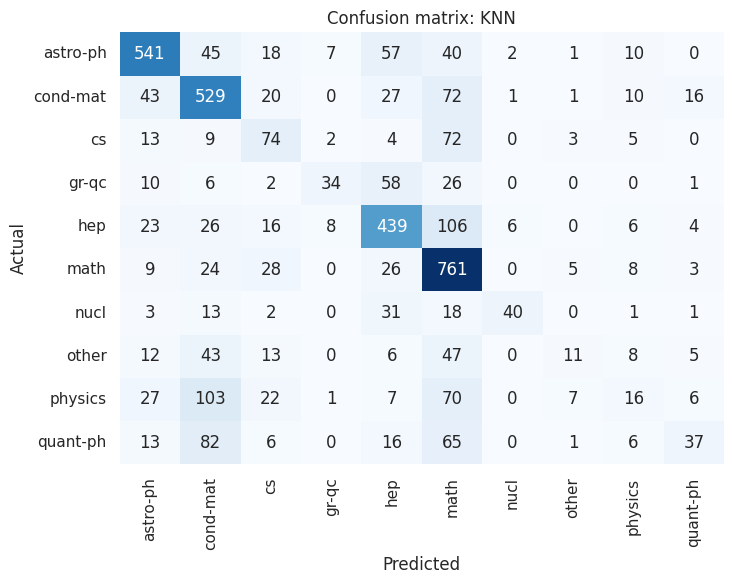

Decision Tree
              precision    recall  f1-score   support

    astro-ph       0.81      0.66      0.73       721
    cond-mat       0.38      0.86      0.52       719
          cs       0.38      0.24      0.30       182
       gr-qc       0.60      0.19      0.29       137
         hep       0.71      0.54      0.61       634
        math       0.63      0.69      0.66       864
        nucl       0.71      0.31      0.43       109
       other       0.00      0.00      0.00       145
     physics       0.18      0.05      0.08       259
    quant-ph       0.53      0.15      0.24       226

    accuracy                           0.55      3996
   macro avg       0.49      0.37      0.39      3996
weighted avg       0.56      0.55      0.52      3996



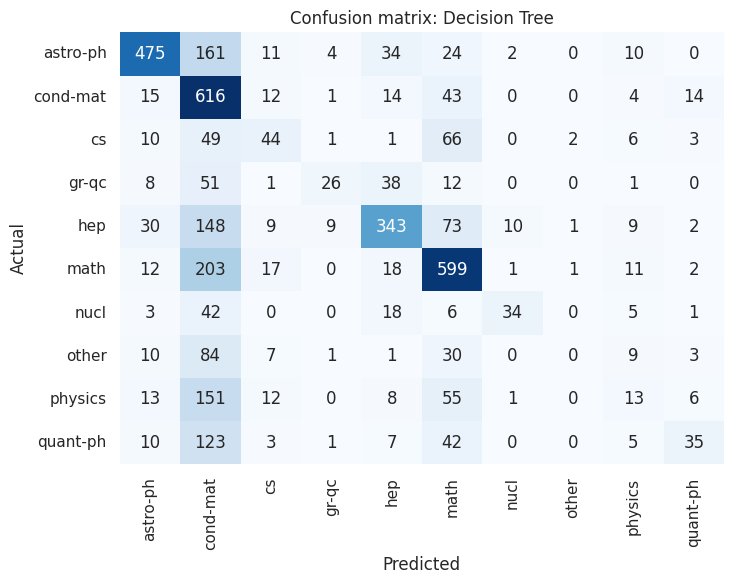

Logistic Regression
              precision    recall  f1-score   support

    astro-ph       0.80      0.76      0.78       721
    cond-mat       0.65      0.76      0.70       719
          cs       0.44      0.27      0.33       182
       gr-qc       0.76      0.30      0.43       137
         hep       0.74      0.65      0.69       634
        math       0.53      0.93      0.67       864
        nucl       0.74      0.48      0.58       109
       other       0.50      0.04      0.08       145
     physics       0.29      0.07      0.11       259
    quant-ph       0.58      0.23      0.33       226

    accuracy                           0.63      3996
   macro avg       0.60      0.45      0.47      3996
weighted avg       0.63      0.63      0.60      3996



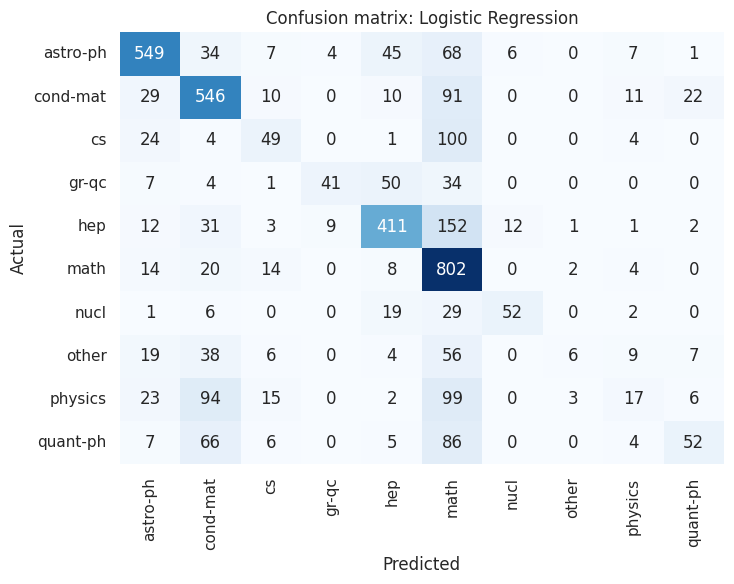

,Accuracy,Precision,Recall,F1,Macro F1
Model,,,,,
KNN,0.6211,0.6002,0.6211,0.5861,0.4534
Decision Tree,0.5468,0.5624,0.5468,0.5197,0.3862
Logistic Regression,0.6319,0.6288,0.6319,0.5962,0.4702


In [25]:
models = {"KNN": knn, "Decision Tree": tree, "Logistic Regression": logreg}
preds, summary = {}, []
for name, m in models.items():
    p = m.predict(Xte)
    preds[name] = p
    pr, rc, f1w, _ = precision_recall_fscore_support(yte, p, average="weighted", zero_division=0)
    summary.append({"Model": name, "Accuracy": accuracy_score(yte, p), "Precision": pr, "Recall": rc, "F1": f1w,
                    "Macro F1": f1_score(yte, p, average="macro", zero_division=0)})
    print("=" * 70); print(name); print(classification_report(yte, p, zero_division=0))

    cm = confusion_matrix(yte, p, labels=classes)
    plt.figure(figsize=(7.5, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix: {name}")
    save_fig3("w3_cm_" + name.lower().replace(" ", "_"))

comparison = pd.DataFrame(summary).set_index("Model")
display(comparison.round(4))

Best model (highest macro F1): Logistic Regression | accuracy: 0.6319
Best by accuracy: Logistic Regression


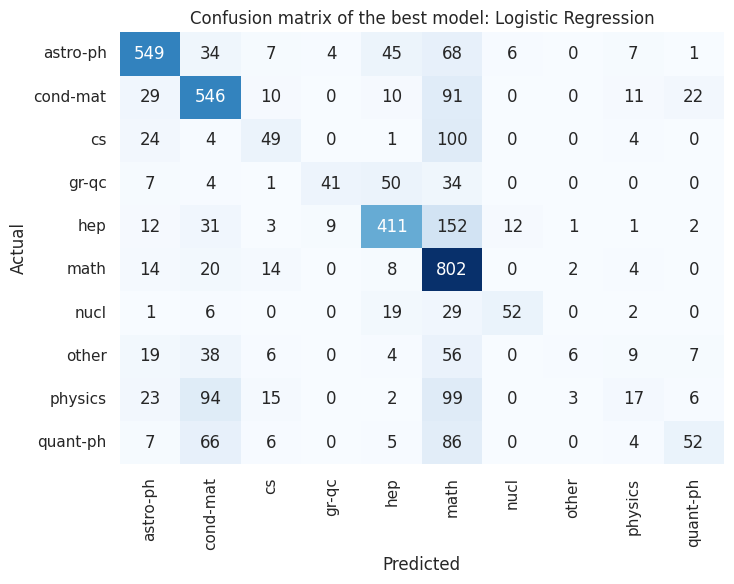


Weakest classes (recall):
other       0.041
physics     0.066
quant-ph    0.230
dtype: float64

Most common mistakes (actual -> predicted, count):
  hep -> math: 152
  cs -> math: 100
  physics -> math: 99


In [26]:
best_name = comparison["Macro F1"].idxmax()
print("Best model (highest macro F1):", best_name, "| accuracy:", round(comparison.loc[best_name, "Accuracy"], 4))
print("Best by accuracy:", comparison["Accuracy"].idxmax())

best_pred = preds[best_name]
cm = confusion_matrix(yte, best_pred, labels=classes)
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix of the best model: {best_name}")
save_fig3("w3_cm_best")

recall_per_class = pd.Series(np.diag(cm) / cm.sum(axis=1), index=classes).sort_values()
precision_per_class = pd.Series(np.diag(cm) / np.maximum(cm.sum(axis=0), 1), index=classes)
off = [(classes[i], classes[j], int(cm[i, j])) for i in range(len(classes)) for j in range(len(classes)) if i != j]
top_confusions = sorted(off, key=lambda t: -t[2])[:3]
print("\nWeakest classes (recall):"); print(recall_per_class.head(3).round(3))
print("\nMost common mistakes (actual -> predicted, count):")
for a, b, n in top_confusions:
    print(f"  {a} -> {b}: {n}")

,Accuracy,Macro F1,Gap (Accuracy - Macro F1)
Model,,,
KNN,0.6211,0.4534,0.1677
Decision Tree,0.5468,0.3862,0.1606
Logistic Regression,0.6319,0.4702,0.1617
Always biggest class,0.2162,0.0356,0.1807


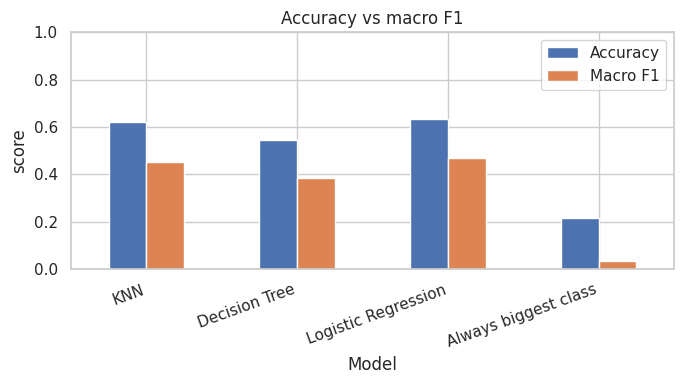

In [27]:
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
dp = dummy.predict(Xte)
base = {"Accuracy": accuracy_score(yte, dp), "Macro F1": f1_score(yte, dp, average="macro", zero_division=0)}
bonus = comparison[["Accuracy", "Macro F1"]].copy()
bonus.loc["Always biggest class"] = [base["Accuracy"], base["Macro F1"]]
bonus["Gap (Accuracy - Macro F1)"] = bonus["Accuracy"] - bonus["Macro F1"]
display(bonus.round(4))

bonus[["Accuracy", "Macro F1"]].plot(kind="bar", figsize=(7, 4), color=["#4c72b0", "#dd8452"])
plt.xticks(rotation=20, ha="right"); plt.ylim(0, 1); plt.title("Accuracy vs macro F1"); plt.ylabel("score")
save_fig3("w3_acc_vs_f1")

In [28]:
y_len_train = df.loc[Xtr.index, "abstract_words"]
y_len_test = df.loc[Xte.index, "abstract_words"]
cols = [c for c in Xtr.columns if c != "num__abstract_words"]     # do not give the answer as an input

lin = LinearRegression().fit(Xtr[cols], y_len_train)
pred_len = lin.predict(Xte[cols])
mean_guess = np.full(len(y_len_test), y_len_train.mean())
w3["linear"] = {"r2": float(r2_score(y_len_test, pred_len)), "mae": float(mean_absolute_error(y_len_test, pred_len)),
                "baseline_mae": float(mean_absolute_error(y_len_test, mean_guess))}
print(f"Linear Regression: R2 = {w3['linear']['r2']:.3f}, MAE = {w3['linear']['mae']:.1f} words (always-average baseline MAE = {w3['linear']['baseline_mae']:.1f} words)")

Linear Regression: R2 = 0.329, MAE = 40.6 words (always-average baseline MAE = 50.5 words)


In [29]:
w3["comparison"] = comparison.round(4).reset_index().to_dict("records")
w3["best_model"] = best_name
w3["best_cm"] = {"classes": classes, "matrix": cm.tolist()}
w3["recall_per_class"] = {k: round(float(v), 4) for k, v in recall_per_class.items()}
w3["top_confusions"] = [{"actual": a, "predicted": b, "count": n} for a, b, n in top_confusions]
w3["baseline"] = {k: round(float(v), 4) for k, v in base.items()}
with open("outputs/results_week3.json", "w") as f:
    json.dump(w3, f, indent=2)
print("Saved outputs/results_week3.json")

Saved outputs/results_week3.json
